# ITCHI con MSWEP V3.16 a 6 h: rampas R3/R4 y radio ROCLOUD con piso W06

Casos: Cristóbal 2020 (NA) y Odile 2014 (EP); un caso por corrida (`CASE`). Base: `02_itchi_rocloud_pa21_chavas.ipynb`.

## Diseño: 2 radios × 2 rampas = 4 experimentos por caso

| | rampa `R3` (Q90/Q95/Q99) | rampa `R4` (Q75/Q90/Q95/Q99) |
|---|---|---|
| radio `w06` | `w06 · R3` (referencia) | `w06 · R4` |
| radio `rocloud_w06floor` | `rocloud_w06floor · R3` | `rocloud_w06floor · R4` |

- **Radios de atribución.** `w06`: radio W06 con metodología PA21, $R(2\ \mathrm{m\,s^{-1}})$, simétrico (el modo `pa21` del notebook base). `rocloud_w06floor`: ROCLOUD por cuadrante; si el cuadrante ROCLOUD es menor que el radio W06, o no tiene detección, se sustituye por el radio W06. Se elimina Chavas.
- **Rampas.** Las dos usan los mismos percentiles por píxel de los acumulados de 6 h de MSWEP V3.16 (mayo–noviembre). Solo cambian los nodos (sección 5).
- **Precipitación.** Un acumulado de 6 h por tiempo sinóptico, leído de `D:/MSWEP_V316_6H/mswep_v3_6h_YYYY.nc` (los mismos archivos de las declaratorias), con ventana $(T-6\,\mathrm{h},\,T]$.
- **Común a los cuatro experimentos.** Radio directo (R34 observado; `H.direct_radii_km`), viento (perfil radial de `wind.py`, como en el notebook base), snapshots y climatología. Chavas solo intervenía como radio de atribución, así que el viento no cambia.
- **Sin tocar el paquete.** $H_P$ se calcula aquí con la rampa elegida y se entrega al pipeline con $(Q_{90}, Q_{95}, Q_{99}) = (0,\ 0.5,\ 1)$. Con esos valores la rampa del paquete devuelve el mismo número que recibe, de modo que la resolución de radios, las máscaras y el control de calidad son los del pipeline. Se verifica con `assert`.

## Propiedades que se verifican en el notebook

1. $R^{\mathrm{floor}}_q \geq R^{\mathrm{W06}}$, por lo que la región de atribución de `rocloud_w06floor` contiene a la de `w06`, y $\Delta\mathrm{ITCHI}(\mathrm{floor}-\mathrm{w06}) \geq 0$ celda a celda.
2. Con los nodos de `R4`, $H_P^{R4} \geq H_P^{R3}$ para cualquier $P$; la diferencia es nula para $P \geq Q_{95}$ y máxima (0.25) en $P = Q_{90}$. Por tanto $\Delta\mathrm{ITCHI}(R4-R3) \geq 0$.

In [22]:
import os
import re
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from itchi.aggregation import compute_event_accumulated, compute_event_max
from itchi.config import get_project_root, load_default_config
from itchi.constants import DEFAULT_EPSILON, QUADRANTS
from itchi.mswep import infer_mswep_lat_lon_names, subset_mswep_domain
from itchi.pipeline import compute_itchi_snapshot_from_grid
from itchi.plotting import (
    SIAT_DANGER_LABELS,
    MapStyle,
    configure_map_axis,
    plot_itchi_field,
    plot_itchi_siat_levels,
)
from itchi.precipitation import compute_precipitation_hazard
from itchi.radii import standardize_quadrant_radii
from itchi.rocloud import DEFAULT_ROCLOUD_COLUMN_MAP
from itchi.tracks import DEFAULT_R34_COLUMN_MAP

ROOT = get_project_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import itchi.itchi_size_helpers as H  # noqa: E402

## 0. Parámetros

In [23]:
CFG = load_default_config()
CASES = {
    "CRISTOBAL2020": dict(name="CRISTOBAL", season=2020, basin="NA", atcf="AL032020",
                          t_map="2020-06-04 00:00"),
    "ODILE2014": dict(name="ODILE", season=2014, basin="EP", atcf="EP152014",
                      t_map="2014-09-15 00:00"),
}

In [24]:
CASE = "CRISTOBAL2020"
C = CASES[CASE]
T_MAP = pd.Timestamp(C["t_map"])            # tiempo para los mapas por snapshot

IBTRACS_FILE = ROOT / CFG["paths"]["tracks"] / f"IBTrACS.{C['basin']}.v04r01.nc"
ROCLOUD_FILE = ROOT / "data" / "external" / "Rocloud" / f"ROCLOUD_{C['basin']}.csv"


def local_path(path) -> Path:
    # "D:/..." -> "/mnt/d/..." en WSL/Linux; sin cambios en Windows
    s = str(path).replace("\\", "/")
    if os.name != "nt" and re.match(r"^[A-Za-z]:/", s):
        return Path(f"/mnt/{s[0].lower()}") / s[3:]
    return Path(s)


# Acumulados de 6 h (scripts/mswep_v3_6h_accum.py): "precipitation" en mm,
# time = fin de la ventana, ventana (T-6h, T], solo mayo-noviembre
MSWEP_6H_DIR = local_path("D:/MSWEP_V316_6H")
MSWEP_6H_PATTERN = "mswep_v3_6h_{year}.nc"
PRECIP_VAR = "precipitation"
assert MSWEP_6H_DIR.is_dir(), f"no existe {MSWEP_6H_DIR}"

# Percentiles por píxel de los acumulados de 6 h
CLIM_FILE = ROOT / "data" / "processed" / "mswep_v3_6h_percentiles_may_nov.nc"
CLIM_VAR = "p_wet"                          # percentiles de periodos de 6 h húmedos
CLIM_DOMAIN = dict(lon_min=-140.0, lon_max=-60.0, lat_min=5.0, lat_max=35.0)
PAD_DEG = 12.0

# Rampas de H_P: {percentil: H_P en el nodo}, en orden creciente de percentil
RAMPS = {
    "R3": {"Q90": 0.0, "Q95": 0.5, "Q99": 1.0},                  # vigente
    "R4": {"Q75": 0.0, "Q90": 0.25, "Q95": 0.5, "Q99": 1.0},     # propuesta
}

# Radios de atribución
W06_MODE = "pa21"                           # modo de H.attribution_radii_km para W06
ATTRIBUTIONS = ("w06", "rocloud_w06floor")
EXPERIMENTS = [(a, r) for a in ATTRIBUTIONS for r in RAMPS]
REFERENCE = ("w06", "R3")


def label(exp) -> str:
    return f"{exp[0]} · {exp[1]}"


FIG_DIR = ROOT / CFG["outputs"]["figures"] / f"itchi_v316_6h_{CASE.lower()}"
DIAG_DIR = ROOT / CFG["outputs"]["diagnostics"] / "itchi_v316_6h"
OUT_DIR = ROOT / CFG["outputs"]["event_products"]
for d in (FIG_DIR, DIAG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Trayectoria y radios (IBTrACS, W06 PA21, ROCLOUD)

In [25]:
track = H.load_case_track(IBTRACS_FILE, ROCLOUD_FILE, C["name"], C["season"], C["atcf"])

ROC_COLS = {q: DEFAULT_ROCLOUD_COLUMN_MAP[q] for q in QUADRANTS}
missing_cols = [c for c in ROC_COLS.values() if c not in track]
assert not missing_cols, (f"faltan columnas ROCLOUD por cuadrante {missing_cols}; "
                          f"columnas disponibles: {[c for c in track if 'rocloud' in c.lower()]}")

# Solo snapshots con radio W06 válido (requisito de ambos modos)
has_w06 = np.array([H.attribution_radii_km(row, W06_MODE)[0] is not None
                    for _, row in track.iterrows()])
print(f"snapshots: {len(track)} | con radio W06 válido: {int(has_w06.sum())}")
track_eval = track[has_w06].reset_index(drop=True)
track[["time", "vmax_kt", "r34_obs_km", "pa21_r2_km", "rocloud_mean_km"]].round(1)

snapshots: 43 | con radio W06 válido: 43


/tmp/ipykernel_3341/2173967345.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  track[["time", "vmax_kt", "r34_obs_km", "pa21_r2_km", "rocloud_mean_km"]].round(1)


,time,vmax_kt,r34_obs_km,pa21_r2_km,rocloud_mean_km
0,2020-06-01 18:00:00,25.0,NaN,661.3,689.2
1,2020-06-02 00:00:00,25.0,NaN,662.6,703.8
2,2020-06-02 06:00:00,30.0,NaN,705.8,788.3
3,2020-06-02 12:00:00,35.0,111.099998,737.5,701.7
4,2020-06-02 18:00:00,40.0,111.099998,759.8,785.4
5,2020-06-03 00:00:00,45.0,101.900002,776.7,932.9
6,2020-06-03 06:00:00,50.0,83.300003,789.5,883.9
7,2020-06-03 12:00:00,50.0,83.300003,788.8,907.4
8,2020-06-03 18:00:00,45.0,83.300003,773.0,782.9
9,2020-06-04 00:00:00,40.0,74.099998,752.6,726.5


## 2. Regla de sustitución de radios por cuadrante

Para cada snapshot y cuadrante $q \in \{\mathrm{NE}, \mathrm{SE}, \mathrm{SW}, \mathrm{NW}\}$:

$$
R^{\mathrm{w06}}_{q} = R_{\mathrm{W06}}, \qquad
R^{\mathrm{floor}}_{q} =
\begin{cases}
R_{\mathrm{ROC},q} & \text{si } R_{\mathrm{ROC},q} \text{ existe y } R_{\mathrm{ROC},q} \geq R_{\mathrm{W06}} \\
R_{\mathrm{W06}} & \text{si } R_{\mathrm{ROC},q} < R_{\mathrm{W06}} \text{ (piso)} \\
R_{\mathrm{W06}} & \text{si el cuadrante no tiene detección ROCLOUD}
\end{cases}
$$

es decir, $R^{\mathrm{floor}}_{q} = \max(R_{\mathrm{ROC},q},\ R_{\mathrm{W06}})$ con $R_{\mathrm{ROC},q}$ faltante tratado como $-\infty$. $R_{\mathrm{W06}}$ es el radio que devuelve `H.attribution_radii_km(row, "pa21")`. Al final se impone $R_q \geq R_{\mathrm{dir},q}$, condición del control de calidad del pipeline ($R_{34} \le R_{\mathrm{atr}}$); los cuadrantes recortados por ella se registran.

A diferencia del modo `rocloud` del notebook base, aquí no se rellenan los cuadrantes inválidos con la media de los válidos: el piso W06 ocupa ese papel.

In [26]:
STATUS_ORDER = ("rocloud", "piso_w06", "sin_rocloud")


def rocloud_raw_km(row: pd.Series) -> dict:
    # ROCLOUD por cuadrante; 0 o negativo = sin detección
    out = {}
    for q, col in ROC_COLS.items():
        v = float(row[col]) if pd.notna(row[col]) else np.nan
        out[q] = v if v > 0 else np.nan
    return out


def w06_radii_km(row: pd.Series) -> dict | None:
    radii, _ = H.attribution_radii_km(row, W06_MODE)
    return None if radii is None else standardize_quadrant_radii(radii)


def direct_radii_km(row: pd.Series) -> dict:
    return standardize_quadrant_radii(H.direct_radii_km(row))


def attribution_radii_km(row: pd.Series, attribution: str):
    # Devuelve (radios finales por cuadrante, estado por cuadrante, cuadrantes recortados a R_dir)
    w06 = w06_radii_km(row)
    if w06 is None:
        return None, None, []
    if attribution == "w06":
        radii = dict(w06)
        status = {q: "w06" for q in QUADRANTS}
    elif attribution == "rocloud_w06floor":
        roc = rocloud_raw_km(row)
        radii, status = {}, {}
        for q in QUADRANTS:
            if not np.isfinite(roc[q]):
                radii[q], status[q] = w06[q], "sin_rocloud"
            elif roc[q] < w06[q]:
                radii[q], status[q] = w06[q], "piso_w06"
            else:
                radii[q], status[q] = roc[q], "rocloud"
    else:
        raise ValueError(attribution)
    direct = direct_radii_km(row)
    clipped = [q for q in QUADRANTS if radii[q] < direct[q]]
    return {q: max(radii[q], direct[q]) for q in QUADRANTS}, status, clipped


rad_rows = []
for _, row in track_eval.iterrows():
    w06 = w06_radii_km(row)
    roc = rocloud_raw_km(row)
    direct = direct_radii_km(row)
    for attribution in ATTRIBUTIONS:
        radii, status, clipped = attribution_radii_km(row, attribution)
        for q in QUADRANTS:
            rad_rows.append(dict(time=row["time"], attribution=attribution, quadrant=q,
                                 R_dir_km=direct[q], R_W06_km=w06[q], R_ROC_km=roc[q],
                                 R_final_km=radii[q], status=status[q],
                                 recortado_a_Rdir=q in clipped))
radii_log = pd.DataFrame(rad_rows)
radii_log.to_csv(DIAG_DIR / f"radios_atribucion_{CASE.lower()}.csv", index=False)

floor = radii_log[radii_log["attribution"] == "rocloud_w06floor"]
print("estado de los cuadrantes en rocloud_w06floor:")
print(floor["status"].value_counts().reindex(STATUS_ORDER, fill_value=0).to_string())
with_roc = floor["status"] != "sin_rocloud"
print(f"cuadrantes con ROCLOUD sustituidos por W06: {(floor.loc[with_roc, 'status'] == 'piso_w06').mean():.1%}")
print("cuadrantes recortados a R_dir:", radii_log.groupby("attribution")["recortado_a_Rdir"].sum().to_dict())

# Tabla del snapshot de los mapas
(floor[floor["time"] == T_MAP]
 .set_index("quadrant")[["R_dir_km", "R_W06_km", "R_ROC_km", "R_final_km", "status"]].round(1))

estado de los cuadrantes en rocloud_w06floor:
status
rocloud        71
piso_w06       44
sin_rocloud    57
cuadrantes con ROCLOUD sustituidos por W06: 38.3%
cuadrantes recortados a R_dir: {'rocloud_w06floor': 0, 'w06': 0}


,R_dir_km,R_W06_km,R_ROC_km,R_final_km,status
quadrant,,,,,
RNE,92.6,752.6,791.3,791.3,rocloud
RSE,55.6,752.6,763.0,763.0,rocloud
RSW,55.6,752.6,794.1,794.1,rocloud
RNW,92.6,752.6,557.6,752.6,piso_w06


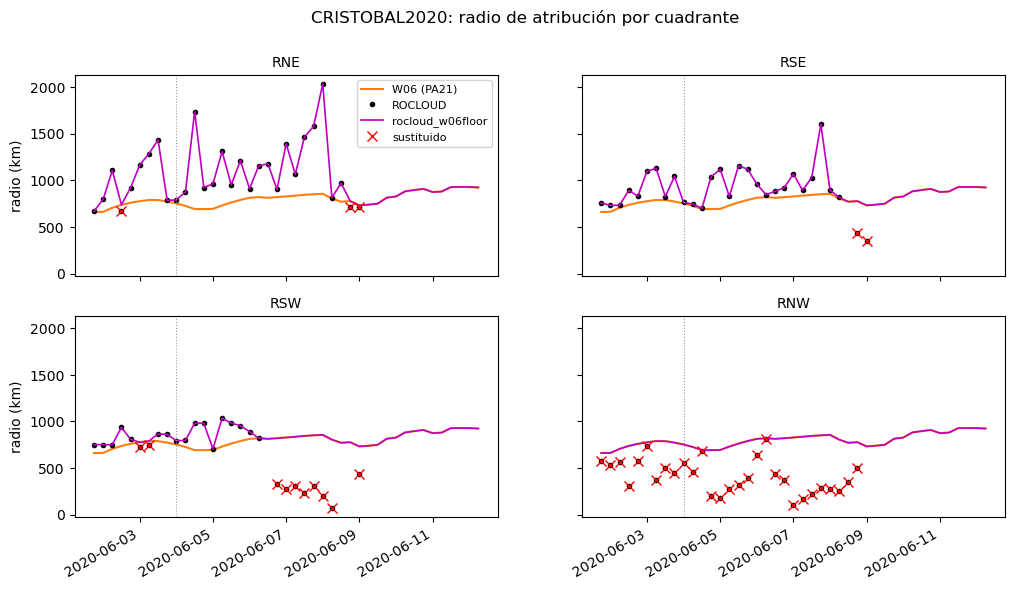

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, q in zip(axes.ravel(), QUADRANTS):
    d = floor[floor["quadrant"] == q]
    ax.plot(d["time"], d["R_W06_km"], "C1-", lw=1.5, label="W06 (PA21)")
    ax.plot(d["time"], d["R_ROC_km"], "k.", ms=6, label="ROCLOUD")
    ax.plot(d["time"], d["R_final_km"], "m-", lw=1.2, label="rocloud_w06floor")
    sub = d["status"] == "piso_w06"
    ax.plot(d.loc[sub, "time"], d.loc[sub, "R_ROC_km"], "rx", ms=7, label="sustituido")
    ax.axvline(T_MAP, color="0.6", ls=":", lw=0.8)
    ax.set_title(q, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("radio (km)")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"{CASE}: radio de atribución por cuadrante")
fig.autofmt_xdate()
fig.savefig(FIG_DIR / "radios_por_cuadrante.png", dpi=150, bbox_inches="tight")

## 3. MSWEP V3.16: acumulados de 6 h

El snapshot del tiempo sinóptico $t$ es `sel(time=t)` en el archivo anual: precipitación de las 6 h previas a la posición IBTrACS. Se exige coincidencia exacta del tiempo y se reportan los NaN (ventanas con horas faltantes).

In [48]:
bbox = dict(
    lon_min=max(float(track_eval["lon"].min()) - PAD_DEG, CLIM_DOMAIN["lon_min"]),
    lon_max=min(float(track_eval["lon"].max()) + PAD_DEG, CLIM_DOMAIN["lon_max"]),
    lat_min=max(float(track_eval["lat"].min()) - PAD_DEG, CLIM_DOMAIN["lat_min"]),
    lat_max=min(float(track_eval["lat"].max()) + PAD_DEG, CLIM_DOMAIN["lat_max"]),
)


def read_6h_snapshots(times: pd.Series) -> xr.DataArray:
    parts = []
    times = pd.Series(pd.to_datetime(times))
    for year, t_year in times.groupby(times.dt.year):
        path = MSWEP_6H_DIR / MSWEP_6H_PATTERN.format(year=year)
        with xr.open_dataset(path) as ds:
            print(path.name, "|", ds[PRECIP_VAR].attrs.get("accumulation_window"),
                  "|", ds[PRECIP_VAR].attrs.get("units"))
            da = subset_mswep_domain(ds[PRECIP_VAR], **bbox)
            missing_t = t_year[~t_year.isin(pd.DatetimeIndex(da["time"].values))]
            assert missing_t.empty, f"tiempos sin acumulado de 6 h: {list(missing_t)}"
            parts.append(da.sel(time=t_year.values).load())
    return xr.concat(parts, dim="time")


P6 = read_6h_snapshots(track_eval["time"])
LAT_NAME, LON_NAME = infer_mswep_lat_lon_names(P6)
P0 = P6.isel(time=0, drop=True)
LON2D, LAT2D = np.meshgrid(P0[LON_NAME].values, P0[LAT_NAME].values)
PRECIP6 = {pd.Timestamp(t): np.asarray(P6.sel(time=t).values, dtype=float)
           for t in P6["time"].values}

nan_frac = pd.Series({t: np.isnan(v).mean() for t, v in PRECIP6.items()})
print(f"{len(PRECIP6)} snapshots | malla {P0.shape} | "
      f"snapshots con NaN: {int((nan_frac > 0).sum())} (máx. {nan_frac.max():.1%})")

DLAT = abs(float(np.diff(P0[LAT_NAME].values[:2])[0]))
DLON = abs(float(np.diff(P0[LON_NAME].values[:2])[0]))
CELL_AREA_KM2 = (np.deg2rad(DLAT) * H.EARTH_RADIUS_KM) * (
    np.deg2rad(DLON) * H.EARTH_RADIUS_KM * np.cos(np.deg2rad(LAT2D)))

mswep_v3_6h_2020.nc | (T-6h, T], T = valid_time | mm
43 snapshots | malla (294, 375) | snapshots con NaN: 0 (máx. 0.0%)


## 4. Percentiles de 6 h por píxel

Se exigen Q75, Q90, Q95 y Q99. Si el archivo no trae P75 (por ejemplo, solo P70), la celda se detiene: no se sustituye ni se interpola, porque cambiaría la rampa evaluada.

Los percentiles deben calcularse sobre periodos de 6 h húmedos. Sobre todos los periodos, Q75 es casi 0 mm en buena parte del dominio y `R4` se activaría con cualquier llovizna.

In [29]:
clim_ds = xr.open_dataset(CLIM_FILE)
print("variables:", list(clim_ds.data_vars), "| dims:", dict(clim_ds.sizes))
assert CLIM_VAR in clim_ds, f"{CLIM_VAR} no está en {CLIM_FILE.name}"
pw = clim_ds[CLIM_VAR]
qdim = next(d for d in pw.dims if d not in infer_mswep_lat_lon_names(pw))
levels = np.asarray(pw[qdim].values, dtype=float)
scale = 100.0 if levels.max() <= 1.0 else 1.0
clim = xr.Dataset({f"Q{v * scale:g}": pw.sel({qdim: v}, drop=True) for v in levels})
print("percentiles disponibles:", list(clim.data_vars), "| unidades:", pw.attrs.get("units"))

REQUIRED_Q = sorted({k for nodes in RAMPS.values() for k in nodes}, key=lambda k: float(k[1:]))
missing_q = [k for k in REQUIRED_Q if k not in clim]
assert not missing_q, f"faltan {missing_q} en {CLIM_FILE.name}: recalcula los percentiles incluyéndolos"

clim_lat, clim_lon = infer_mswep_lat_lon_names(clim)
clim = subset_mswep_domain(clim.rename({clim_lat: LAT_NAME, clim_lon: LON_NAME}), **bbox)
clim = clim.reindex_like(P0, method="nearest", tolerance=1e-3)   # misma malla, sin interpolar
Q = {k: np.asarray(clim[k].values, dtype=float) for k in REQUIRED_Q}
assert all(v.shape == LON2D.shape for v in Q.values())

CLIM_OK = np.all([np.isfinite(v) for v in Q.values()], axis=0)
ordered = np.all([Q[a] <= Q[b] for a, b in zip(REQUIRED_Q[:-1], REQUIRED_Q[1:])], axis=0)
print(f"cobertura: {CLIM_OK.mean():.1%} | orden {' ≤ '.join(REQUIRED_Q)}: {ordered[CLIM_OK].mean():.2%}")
pd.Series({k: np.nanmedian(v) for k, v in Q.items()}, name="mediana (mm/6 h)").round(2)

variables: ['p_wet', 'p_wet_raw', 'n_wet', 'frac_above_p_wet', 'p_all', 'n_valid', 'wet_freq', 'freq_above_abs', 'p_wet_hour', 'p_wet_raw_hour', 'n_wet_hour', 'p_all_hour'] | dims: {'quantile': 5, 'lat': 300, 'lon': 800, 'threshold': 4, 'hour': 4}
percentiles disponibles: ['Q75', 'Q90', 'Q95', 'Q99', 'Q99.9'] | unidades: mm (6 h)-1
cobertura: 96.5% | orden Q75 ≤ Q90 ≤ Q95 ≤ Q99: 100.00%


Q75    10.68
Q90    21.96
Q95    31.88
Q99    56.79
Name: mediana (mm/6 h), dtype: float64

## 5. Rampas de peligro de precipitación $H_P$

### Forma general

Una rampa es una lista de nodos $(Q_k, h_k)$, $k = 1, \dots, K$, con $Q_1 \le \dots \le Q_K$ (percentiles locales del píxel) y $0 \le h_1 \le \dots \le h_K = 1$. Para la precipitación de 6 h $P$ del píxel:

$$
H_P(P) =
\begin{cases}
0, & P < Q_1 \\[4pt]
h_k + \left(h_{k+1} - h_k\right)\,\dfrac{P - Q_k}{\max\left(Q_{k+1} - Q_k,\ \varepsilon\right)}, & Q_k \le P < Q_{k+1} \\[10pt]
h_K = 1, & P \ge Q_K
\end{cases}
$$

con $\varepsilon = 10^{-6}$ mm para píxeles donde dos percentiles coinciden. Los píxeles sin percentiles válidos reciben $H_P = 0$ y se contabilizan.

### R3 (vigente): nodos $(Q_{90}, 0),\ (Q_{95}, 0.5),\ (Q_{99}, 1)$

$$
H_P^{R3} =
\begin{cases}
0, & P < Q_{90} \\
0.5\,\dfrac{P - Q_{90}}{Q_{95} - Q_{90}}, & Q_{90} \le P < Q_{95} \\[8pt]
0.5 + 0.5\,\dfrac{P - Q_{95}}{Q_{99} - Q_{95}}, & Q_{95} \le P < Q_{99} \\[8pt]
1, & P \ge Q_{99}
\end{cases}
$$

### R4 (propuesta): nodos $(Q_{75}, 0),\ (Q_{90}, 0.25),\ (Q_{95}, 0.5),\ (Q_{99}, 1)$

$$
H_P^{R4} =
\begin{cases}
0, & P < Q_{75} \\
0.25\,\dfrac{P - Q_{75}}{Q_{90} - Q_{75}}, & Q_{75} \le P < Q_{90} \\[8pt]
0.25 + 0.25\,\dfrac{P - Q_{90}}{Q_{95} - Q_{90}}, & Q_{90} \le P < Q_{95} \\[8pt]
0.5 + 0.5\,\dfrac{P - Q_{95}}{Q_{99} - Q_{95}}, & Q_{95} \le P < Q_{99} \\[8pt]
1, & P \ge Q_{99}
\end{cases}
$$

### Cómo se asignaron los valores de los nodos

`R4` conserva los dos nodos superiores de `R3` ($Q_{95} \to 0.5$, $Q_{99} \to 1$), así que la lluvia muy intensa se califica igual en ambas rampas. Lo que cambia es la parte baja: el inicio de la rampa baja de $Q_{90}$ a $Q_{75}$, y $Q_{90}$ pasa de 0 a 0.25. Con $f_{a,b} = (P - Q_a)/(Q_b - Q_a)$:

$$
H_P^{R4} - H_P^{R3} =
\begin{cases}
0, & P < Q_{75} \\
0.25\, f_{75,90}, & Q_{75} \le P < Q_{90} \\
0.25\,\left(1 - f_{90,95}\right), & Q_{90} \le P < Q_{95} \\
0, & P \ge Q_{95}
\end{cases}
$$

La diferencia es nula fuera de $[Q_{75}, Q_{95})$, nunca es negativa y su máximo es 0.25, en $P = Q_{90}$. La alternativa equiespaciada $(0,\ 1/3,\ 2/3,\ 1)$ también cumple $H_P^{R4} \ge H_P^{R3}$, pero eleva además el tramo $[Q_{95}, Q_{99})$, y entonces la comparación ya no aísla el efecto del umbral bajo.

### Cómo entra $H_P$ al pipeline

`compute_precipitation_hazard(x, 0, 0.5, 1)` aplica R3 con $Q_{90}=0$, $Q_{95}=0.5$, $Q_{99}=1$ a un valor $x \in [0,1]$: para $x < 0.5$ da $0.5\,x/0.5 = x$, y para $0.5 \le x < 1$ da $0.5 + 0.5\,(x-0.5)/0.5 = x$. Es la identidad, de modo que pasar `precipitation=H_P` con esos tres valores hace que el pipeline use exactamente el $H_P$ de la rampa elegida.

In [30]:
def ramp_hazard(p, qs: dict, nodes: dict):
    # Interpolación lineal por tramos entre nodos (Q_k, h_k); devuelve (H_P, máscara válida)
    p = np.asarray(p, dtype=float)
    keys = list(nodes)
    qk = [np.asarray(qs[k], dtype=float) for k in keys]
    hk = [float(nodes[k]) for k in keys]
    h = np.zeros(np.broadcast(p, *qk).shape)
    for k in range(len(keys) - 1):
        seg = (p >= qk[k]) & (p < qk[k + 1])
        frac = (p - qk[k]) / np.maximum(qk[k + 1] - qk[k], DEFAULT_EPSILON)
        h = np.where(seg, hk[k] + (hk[k + 1] - hk[k]) * frac, h)
    h = np.where(p >= qk[-1], hk[-1], h)
    valid = np.isfinite(p) & np.all([np.isfinite(q) for q in qk], axis=0)
    return np.clip(np.where(valid, h, 0.0), 0.0, 1.0), valid


# Verificación 1: la rampa del paquete con (0, 0.5, 1) es la identidad en [0, 1]
x = np.linspace(0.0, 1.0, 1001)
assert np.allclose(compute_precipitation_hazard(x, 0.0, 0.5, 1.0), x, atol=1e-9)

# Verificación 2: R3 reproduce compute_precipitation_hazard con P6 y percentiles reales
p_test = PRECIP6[next(iter(PRECIP6))]
h3, ok = ramp_hazard(p_test, Q, RAMPS["R3"])
assert np.allclose(h3[ok], compute_precipitation_hazard(p_test, Q["Q90"], Q["Q95"], Q["Q99"])[ok],
                   atol=1e-6)

HP = {(t, r): ramp_hazard(p, Q, nodes)[0] for t, p in PRECIP6.items() for r, nodes in RAMPS.items()}

# Verificación 3: H_P(R4) >= H_P(R3) en todos los snapshots
assert all((HP[(t, "R4")] >= HP[(t, "R3")] - 1e-12).all() for t in PRECIP6)
print("verificaciones de la rampa: OK")

verificaciones de la rampa: OK


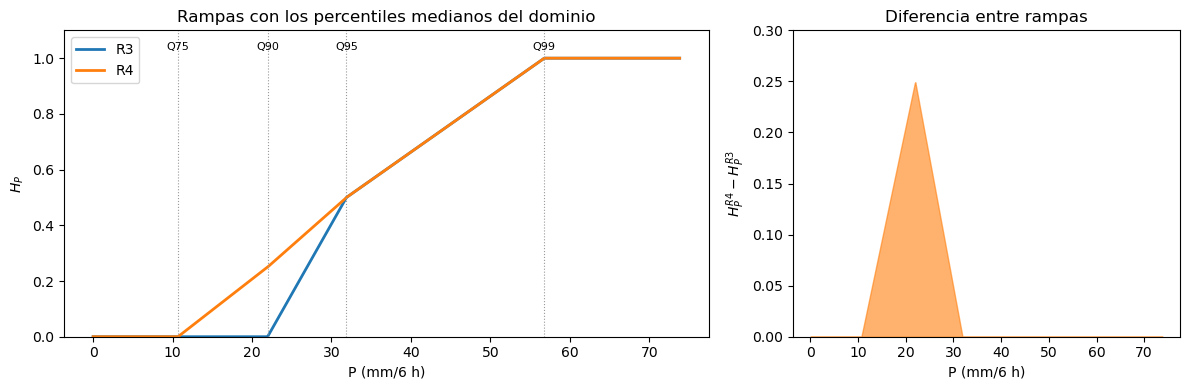

In [31]:
# Rampas en un píxel típico (mediana de cada percentil en el dominio)
q_med = {k: float(np.nanmedian(v)) for k, v in Q.items()}
p_axis = np.linspace(0, 1.3 * q_med[REQUIRED_Q[-1]], 800)
h_r = {r: ramp_hazard(p_axis, q_med, nodes)[0] for r, nodes in RAMPS.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1.2]})
for r, h in h_r.items():
    axes[0].plot(p_axis, h, lw=2, label=r)
for k, v in q_med.items():
    axes[0].axvline(v, color="0.6", ls=":", lw=0.8)
    axes[0].text(v, 1.03, k, ha="center", fontsize=8)
axes[0].set(xlabel="P (mm/6 h)", ylabel="$H_P$", ylim=(0, 1.1),
            title="Rampas con los percentiles medianos del dominio")
axes[0].legend()
axes[1].fill_between(p_axis, h_r["R4"] - h_r["R3"], color="C1", alpha=0.6)
axes[1].set(xlabel="P (mm/6 h)", ylabel="$H_P^{R4} - H_P^{R3}$", ylim=(0, 0.3),
            title="Diferencia entre rampas")
fig.tight_layout()
fig.savefig(FIG_DIR / "rampas.png", dpi=150, bbox_inches="tight")

### Ejemplo paso a paso en un píxel

Se toma el píxel con mayor $P$ dentro de la región de atribución `w06` en `T_MAP` y se aplican ambas rampas con sus propios percentiles. La segunda tabla evalúa las dos rampas en valores característicos de $P$ de ese mismo píxel.

In [32]:
def ramp_step_by_step(p: float, qs: dict, nodes: dict) -> str:
    keys = list(nodes)
    if p < qs[keys[0]]:
        return f"P = {p:.2f} < {keys[0]} = {qs[keys[0]]:.2f}  ->  H_P = 0"
    if p >= qs[keys[-1]]:
        return f"P = {p:.2f} >= {keys[-1]} = {qs[keys[-1]]:.2f}  ->  H_P = 1"
    for a, b in zip(keys[:-1], keys[1:]):
        if qs[a] <= p < qs[b]:
            f = (p - qs[a]) / max(qs[b] - qs[a], DEFAULT_EPSILON)
            h = nodes[a] + (nodes[b] - nodes[a]) * f
            return (f"{a} = {qs[a]:.2f} <= P = {p:.2f} < {b} = {qs[b]:.2f}\n"
                    f"   f = (P - {a}) / ({b} - {a}) = ({p:.2f} - {qs[a]:.2f}) / "
                    f"({qs[b]:.2f} - {qs[a]:.2f}) = {f:.3f}\n"
                    f"   H_P = {nodes[a]:.2f} + ({nodes[b]:.2f} - {nodes[a]:.2f}) * {f:.3f} = {h:.3f}")
    return "sin tramo"


assert (track_eval["time"] == T_MAP).any(), f"T_MAP = {T_MAP} no es un snapshot evaluado"
row_map = track_eval.loc[track_eval["time"] == T_MAP].iloc[0]
radii_w06, _, _ = attribution_radii_km(row_map, "w06")
res_map = compute_itchi_snapshot_from_grid(
    precipitation=HP[(T_MAP, "R3")], q90=0.0, q95=0.5, q99=1.0, lon=LON2D, lat=LAT2D,
    center_lon=float(row_map["lon"]), center_lat=float(row_map["lat"]),
    r34_by_quadrant={q: row_map[DEFAULT_R34_COLUMN_MAP[q]] for q in QUADRANTS}, r34_unit="nm",
    rocloud_by_quadrant=radii_w06, rocloud_unit="km", vmax_kt=float(row_map["vmax_kt"]),
    rmw_km=float(row_map["rmw_km"]) if np.isfinite(row_map["rmw_km"]) else float(row_map["pa21_rmax_km"]))
region = (np.asarray(res_map["M_direct"]) | np.asarray(res_map["M_indirect"])) & CLIM_OK
p_map = np.where(region, PRECIP6[T_MAP], -np.inf)
J, I = np.unravel_index(np.argmax(p_map), p_map.shape)
p_px = float(PRECIP6[T_MAP][J, I])
q_px = {k: float(v[J, I]) for k, v in Q.items()}

print(f"Píxel ({LAT2D[J, I]:.2f}°N, {LON2D[J, I]:.2f}°E), {T_MAP:%Y-%m-%d %H} UTC, P6 = {p_px:.2f} mm")
print("percentiles del píxel (mm/6 h):", {k: round(v, 2) for k, v in q_px.items()})
for r, nodes in RAMPS.items():
    print(f"\n{r}:\n   " + ramp_step_by_step(p_px, q_px, nodes))

p_marks = {"Q75": q_px["Q75"], "(Q75+Q90)/2": 0.5 * (q_px["Q75"] + q_px["Q90"]), "Q90": q_px["Q90"],
           "(Q90+Q95)/2": 0.5 * (q_px["Q90"] + q_px["Q95"]), "Q95": q_px["Q95"],
           "(Q95+Q99)/2": 0.5 * (q_px["Q95"] + q_px["Q99"]), "Q99": q_px["Q99"], "P6 del píxel": p_px}
pd.DataFrame({"P (mm/6 h)": p_marks,
              **{f"H_P {r}": {k: float(ramp_hazard(v, q_px, n)[0]) for k, v in p_marks.items()}
                 for r, n in RAMPS.items()}}).round(3)

Píxel (17.75°N, -91.95°E), 2020-06-04 00 UTC, P6 = 90.84 mm
percentiles del píxel (mm/6 h): {'Q75': 13.88, 'Q90': 26.85, 'Q95': 37.84, 'Q99': 70.54}

R3:
   P = 90.84 >= Q99 = 70.54  ->  H_P = 1

R4:
   P = 90.84 >= Q99 = 70.54  ->  H_P = 1


,P (mm/6 h),H_P R3,H_P R4
Q75,13.883,0.00,0.000
(Q75+Q90)/2,20.368,0.00,0.125
Q90,26.852,0.00,0.250
(Q90+Q95)/2,32.346,0.25,0.375
Q95,37.840,0.50,0.500
(Q95+Q99)/2,54.192,0.75,0.750
Q99,70.544,1.00,1.000
P6 del píxel,90.836,1.00,1.000


## 6. ITCHI por experimento

### Ensamblado del índice (sin cambios respecto al pipeline; $\alpha = \beta = \lambda = \mu = 1$)

Con $r$ la distancia al centro, $R_{\mathrm{dir},q}$ el radio directo (R34 observado) y $R_q$ el radio de atribución del experimento, en el cuadrante $q$ de cada celda:

$$
M_{\mathrm{dir}}: r \le R_{\mathrm{dir},q}, \qquad
M_{\mathrm{ind}}: R_{\mathrm{dir},q} < r \le R_q, \qquad
\text{exterior}: r > R_q
$$

$$
H_{\mathrm{dir}} = 1 - (1 - H_W)(1 - H_P)\ \text{en } M_{\mathrm{dir}}, \qquad
H_{\mathrm{ind}} = H_P\ \text{en } M_{\mathrm{ind}}, \qquad
\mathrm{ITCHI} = 1 - (1 - H_{\mathrm{dir}})(1 - H_{\mathrm{ind}})
$$

Como las máscaras no se solapan, $\mathrm{ITCHI} = H_{\mathrm{dir}}$ en la región directa, $\mathrm{ITCHI} = H_P$ en la indirecta y 0 fuera. Por eso el cambio de rampa se ve tal cual en la región indirecta, y el cambio de radio solo añade (o quita) región indirecta.

Productos de evento: `ITCHI_max` (máximo temporal) e `ITCHI_acc` $= 1 - \prod_t (1 - \mathrm{ITCHI}_t)$.

In [33]:
FIELDS = ("ITCHI", "H_dir", "H_ind", "H_W", "H_P", "M_direct", "M_indirect")
BOOL_FIELDS = ("M_direct", "M_indirect")


def rmw_km(row: pd.Series) -> float:
    return float(row["rmw_km"]) if np.isfinite(row["rmw_km"]) else float(row["pa21_rmax_km"])


def run_snapshot(row: pd.Series, attribution: str, ramp: str):
    radii, status, clipped = attribution_radii_km(row, attribution)
    if radii is None:
        return None, None
    fallback = float(row["pa21_r34_km"]) if np.isfinite(row["pa21_r34_km"]) else None
    result = compute_itchi_snapshot_from_grid(
        precipitation=HP[(row["time"], ramp)], q90=0.0, q95=0.5, q99=1.0,   # identidad: H_P ya calculado
        lon=LON2D, lat=LAT2D, center_lon=float(row["lon"]), center_lat=float(row["lat"]),
        r34_by_quadrant={q: row[DEFAULT_R34_COLUMN_MAP[q]] for q in QUADRANTS}, r34_unit="nm",
        rocloud_by_quadrant=radii, rocloud_unit="km",
        vmax_kt=float(row["vmax_kt"]), rmw_km=rmw_km(row), fallback_direct_radius_km=fallback,
        run_quality_control=True,
    )
    return result, radii


def run_event(attribution: str, ramp: str, rows: pd.DataFrame = None):
    rows = track_eval if rows is None else rows
    fields, times, log = [], [], []
    for _, row in rows.iterrows():
        result, radii = run_snapshot(row, attribution, ramp)
        log.append(dict(time=row["time"], attribution=attribution, ramp=ramp,
                        valid=result is not None,
                        attribution_mean_km=np.mean(list(radii.values())) if radii else np.nan))
        if result is not None:
            fields.append({k: np.asarray(result[k], dtype=bool if k in BOOL_FIELDS else np.float32)
                           for k in FIELDS})
            times.append(row["time"])
    dims = ("time", LAT_NAME, LON_NAME)
    coords = {"time": times, LAT_NAME: P0[LAT_NAME].values, LON_NAME: P0[LON_NAME].values}
    ds = xr.Dataset({k: (dims, np.stack([f[k] for f in fields])) for k in FIELDS}, coords=coords)
    ds["ITCHI_max"] = compute_event_max(ds["ITCHI"], dim="time")
    ds["ITCHI_acc"] = compute_event_accumulated(ds["ITCHI"], dim="time")
    ds.attrs.update(case=CASE, atcf=C["atcf"], attribution=attribution, ramp=ramp,
                    ramp_nodes=str(RAMPS[ramp]), w06=W06_MODE, wind="wind.py",
                    precipitation="MSWEP V3.16 6-h accumulation (T-6h, T]",
                    climatology=f"{CLIM_FILE.name}:{CLIM_VAR}")
    return ds, pd.DataFrame(log)


events, logs = {}, []
for exp in EXPERIMENTS:
    events[exp], log = run_event(*exp)
    logs.append(log)
logs = pd.concat(logs, ignore_index=True)

# Propiedades de diseño: diferencias no negativas por construcción
r_old, r_new = RAMPS
a_ref, a_alt = ATTRIBUTIONS
for a in ATTRIBUTIONS:
    d = events[(a, r_new)]["ITCHI"] - events[(a, r_old)]["ITCHI"]
    print(f"min ΔITCHI ({r_new} − {r_old} | {a}) = {float(d.min()):+.2e}")
for r in RAMPS:
    d = events[(a_alt, r)]["ITCHI"] - events[(a_ref, r)]["ITCHI"]
    print(f"min ΔITCHI ({a_alt} − {a_ref} | {r}) = {float(d.min()):+.2e}")
logs.groupby(["attribution", "ramp"])[["valid"]].sum()

min ΔITCHI (R4 − R3 | w06) = +0.00e+00
min ΔITCHI (R4 − R3 | rocloud_w06floor) = +0.00e+00
min ΔITCHI (rocloud_w06floor − w06 | R3) = +0.00e+00
min ΔITCHI (rocloud_w06floor − w06 | R4) = +0.00e+00


valid
attribution      ramp       
rocloud_w06floor R3       43
                 R4       43
w06              R3       43
                 R4       43

In [34]:
# Ejemplo paso a paso del índice en el mismo píxel, para los cuatro experimentos
it = list(events[REFERENCE]["time"].values).index(np.datetime64(T_MAP))
rows_px = {}
for exp, ev in events.items():
    s = ev.isel(time=it)
    reg = "directa" if bool(s["M_direct"][J, I]) else ("indirecta" if bool(s["M_indirect"][J, I]) else "exterior")
    rows_px[label(exp)] = {"región": reg, "H_W": float(s["H_W"][J, I]), "H_P": float(s["H_P"][J, I]),
                           "H_dir": float(s["H_dir"][J, I]), "H_ind": float(s["H_ind"][J, I]),
                           "ITCHI": float(s["ITCHI"][J, I])}
pd.DataFrame(rows_px).T.round(3)

,región,H_W,H_P,H_dir,H_ind,ITCHI
w06 · R3,indirecta,0.0,1.0,0.0,1.0,1.0
w06 · R4,indirecta,0.0,1.0,0.0,1.0,1.0
rocloud_w06floor · R3,indirecta,0.0,1.0,0.0,1.0,1.0
rocloud_w06floor · R4,indirecta,0.0,1.0,0.0,1.0,1.0


## 7. Mapas del evento: ITCHI_max por experimento y diferencias

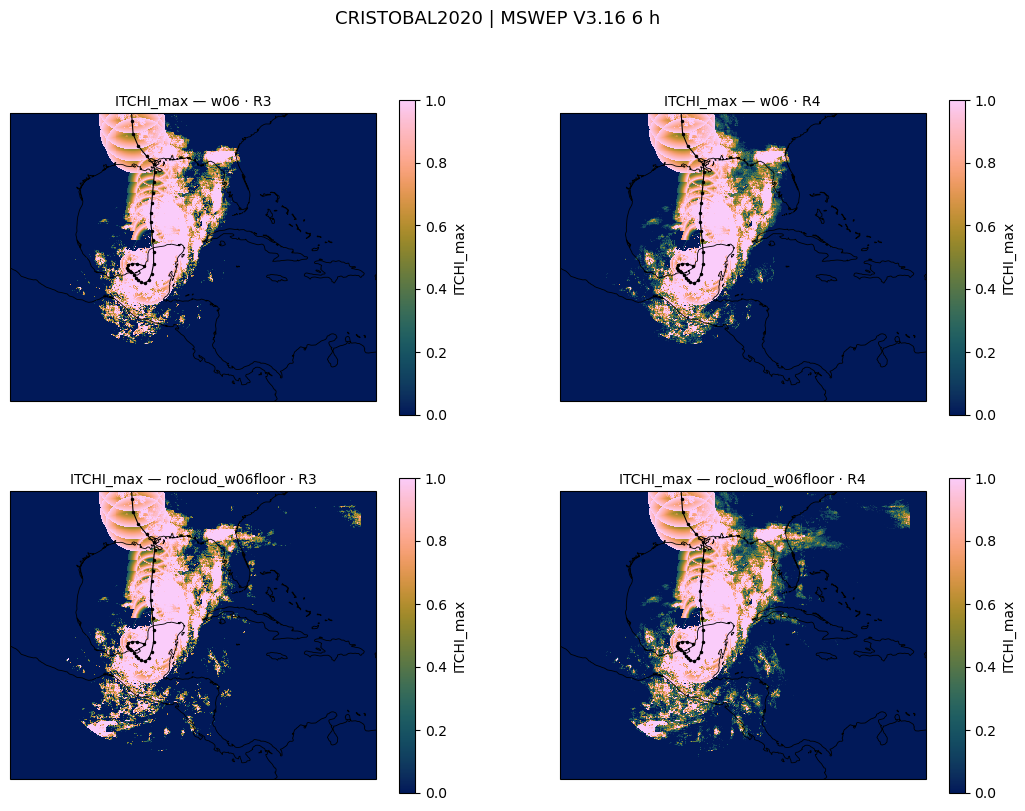

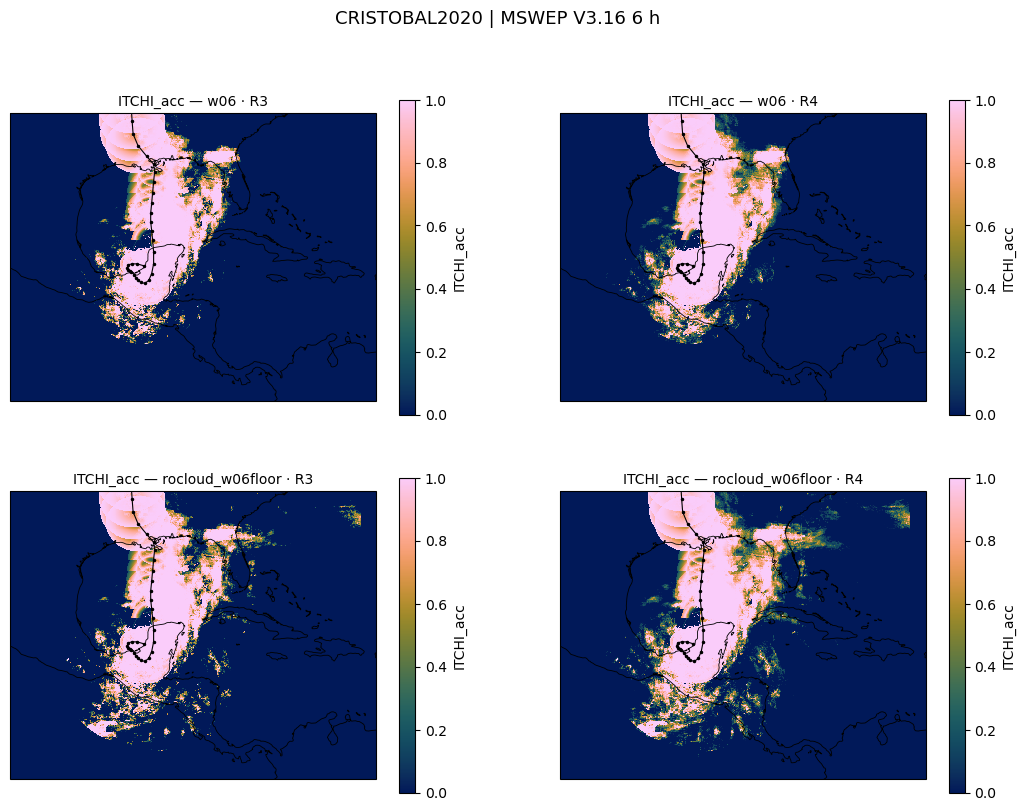

In [35]:
PC = ccrs.PlateCarree()


def map_axes(nrows: int, ncols: int, figsize):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, subplot_kw={"projection": PC},
                             squeeze=False)
    for ax in axes.ravel():
        ax.coastlines(lw=0.6)
        ax.set_extent([bbox["lon_min"], bbox["lon_max"], bbox["lat_min"], bbox["lat_max"]], crs=PC)
        ax.plot(track_eval["lon"], track_eval["lat"], "k.-", lw=0.8, ms=3, transform=PC)
    return fig, axes


for product in ("ITCHI_max", "ITCHI_acc"):
    fig, axes = map_axes(len(ATTRIBUTIONS), len(RAMPS), figsize=(13, 9))
    for i, a in enumerate(ATTRIBUTIONS):
        for j, r in enumerate(RAMPS):
            plot_itchi_field(events[(a, r)][product].values, axes[i, j], lon=LON2D, lat=LAT2D,
                             crs=PC, colorbar_label=product)
            axes[i, j].set_title(f"{product} — {label((a, r))}", fontsize=10)
    fig.suptitle(f"{CASE} | MSWEP V3.16 6 h", fontsize=13)
    fig.savefig(FIG_DIR / f"{product.lower()}_2x2.png", dpi=150, bbox_inches="tight")

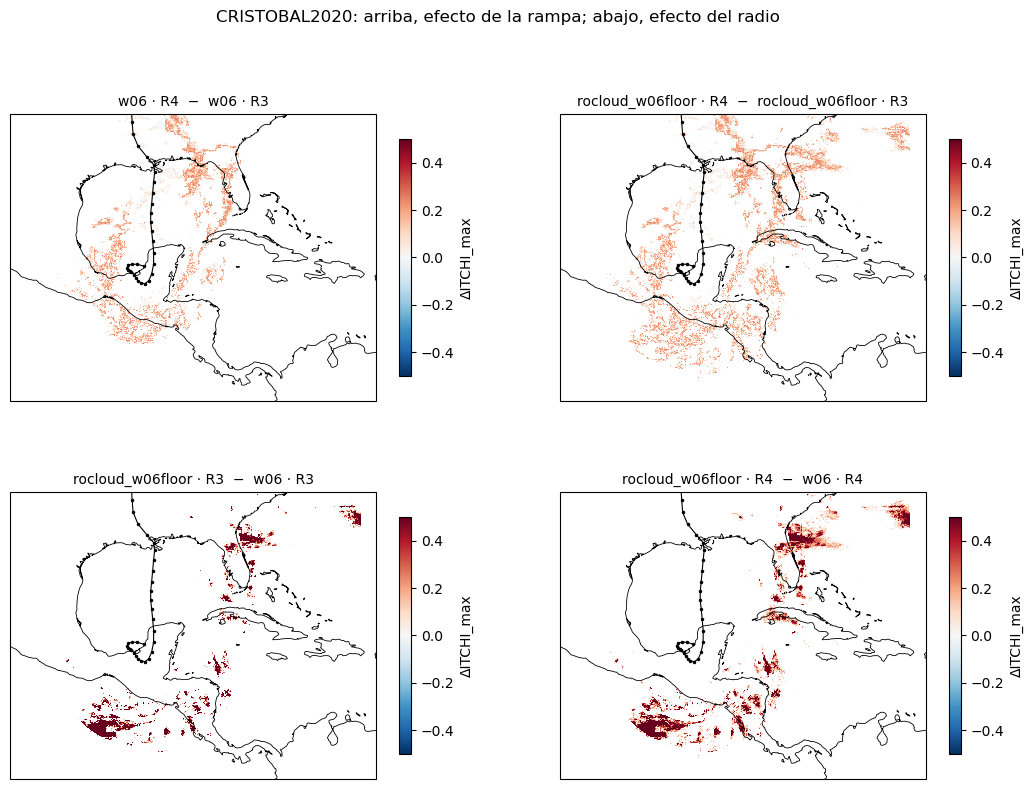

In [36]:
# Fila 1: efecto de la rampa (mismo radio). Fila 2: efecto del radio (misma rampa)
pairs = [((a, r_new), (a, r_old)) for a in ATTRIBUTIONS] + \
        [((a_alt, r), (a_ref, r)) for r in RAMPS]
fig, axes = map_axes(2, 2, figsize=(13, 9))
for ax, (exp, ref) in zip(axes.ravel(), pairs):
    diff = events[exp]["ITCHI_max"] - events[ref]["ITCHI_max"]
    m = ax.pcolormesh(LON2D, LAT2D, np.where(diff.values != 0, diff.values, np.nan),
                      cmap="RdBu_r", vmin=-0.5, vmax=0.5, transform=PC)
    fig.colorbar(m, ax=ax, shrink=0.75, label="ΔITCHI_max")
    ax.set_title(f"{label(exp)}  −  {label(ref)}", fontsize=10)
fig.suptitle(f"{CASE}: arriba, efecto de la rampa; abajo, efecto del radio", fontsize=12)
fig.savefig(FIG_DIR / "itchi_max_diferencias.png", dpi=150, bbox_inches="tight")

## 8. Mapas por snapshot

En cada mapa: radio directo (negro), radio de atribución final del experimento (magenta) y, en `rocloud_w06floor`, el ROCLOUD original (cian discontinuo) y el radio W06 (naranja punteado). Donde el contorno magenta coincide con el naranja, ese cuadrante fue sustituido por W06.

In [37]:
SNAP_TIME = T_MAP                           # posición a mapear (cámbiala libremente)
SNAP_EXPERIMENTS = EXPERIMENTS
SNAP_FIELDS = ("H_P", "H_ind", "ITCHI", "SIAT")
SNAP_HALF_WIDTH_DEG = 14.0
SNAP_STYLE = MapStyle(
    lon_tick_spacing=8.0, lat_tick_spacing=8.0, grid_spacing=4.0,
    grid_color="w", grid_alpha=0.6, label_size=10.0,
)
CBAR = dict(height=0.70, width=0.035, pad=0.03, labelsize=9)   # fracciones del eje del mapa


def snapshot_style(row: pd.Series, base: MapStyle = SNAP_STYLE,
                   half_width: float = SNAP_HALF_WIDTH_DEG) -> MapStyle:
    step = base.lon_tick_spacing
    lon0 = np.floor((row["lon"] - half_width) / step) * step
    lon1 = np.ceil((row["lon"] + half_width) / step) * step
    lat0 = np.floor((row["lat"] - 0.75 * half_width) / step) * step
    lat1 = np.ceil((row["lat"] + 0.75 * half_width) / step) * step
    return replace(base, lon_extent=(lon0, lon1), lat_extent=(lat0, lat1))


def add_small_colorbar(ax, mappable, label_: str, ticks=None, ticklabels=None, **opts):
    o = {**CBAR, **opts}
    cax = ax.inset_axes([1.0 + o["pad"], (1.0 - o["height"]) / 2, o["width"], o["height"]])
    cbar = ax.figure.colorbar(mappable, cax=cax, ticks=ticks)
    cbar.set_label(label_, fontsize=o["labelsize"])
    cbar.ax.tick_params(labelsize=o["labelsize"] - 1)
    if ticklabels is not None:
        cbar.set_ticklabels(ticklabels)
    return cbar


def overlay_radii(ax, row: pd.Series, attribution: str, radii: dict | None) -> None:
    geo = ccrs.Geodetic()
    ax.plot(track_eval["lon"], track_eval["lat"], "k-", lw=0.8, transform=PC, zorder=5)
    x, y = H.quadrant_outline(row["lat"], row["lon"], H.direct_radii_km(row))
    ax.plot(x, y, "k-", lw=1.4, transform=geo, zorder=6, label="radio directo")
    if attribution == "rocloud_w06floor":
        roc = rocloud_raw_km(row)
        if any(np.isfinite(v) for v in roc.values()):
            x, y = H.quadrant_outline(row["lat"], row["lon"], roc)
            ax.plot(x, y, "c--", lw=1.1, transform=geo, zorder=6, label="ROCLOUD original")
        x, y = H.quadrant_outline(row["lat"], row["lon"], w06_radii_km(row))
        ax.plot(x, y, ":", color="C1", lw=1.4, transform=geo, zorder=6, label="W06 (PA21)")
    if radii is not None:
        x, y = H.quadrant_outline(row["lat"], row["lon"], radii)
        ax.plot(x, y, "m-", lw=1.6, transform=geo, zorder=7, label=f"atribución {attribution}")
    ax.plot(row["lon"], row["lat"], "k*", ms=10, transform=PC, zorder=8)


def draw_field(ax, field: str, result: dict, row: pd.Series, attribution: str,
               radii: dict | None, cbar_opts: dict | None = None):
    cbar_opts = cbar_opts or {}
    t = row["time"]
    if field == "P":
        precip = PRECIP6[t]
        mesh = ax.pcolormesh(LON2D, LAT2D, np.where(precip >= 0.1, precip, np.nan), cmap="YlGnBu",
                             shading="auto", transform=PC, zorder=1)
        add_small_colorbar(ax, mesh, "P (6 h, mm)", **cbar_opts)
        for k, ls in (("Q75", "--"), ("Q95", "-")):
            ax.contour(LON2D, LAT2D, precip - Q[k], levels=[0.0], colors="r", linestyles=ls,
                       linewidths=0.7, transform=PC, zorder=5)            # P = Q75, P = Q95
    elif field == "SIAT":
        mesh = plot_itchi_siat_levels(result["ITCHI"], ax, lon=LON2D, lat=LAT2D, crs=PC,
                                      add_colorbar=False, zorder=1)
        add_small_colorbar(ax, mesh, "nivel ITCHI", ticks=np.arange(0.5, 6.5, 1.0),
                           ticklabels=[lab.split(" ", 1)[0] for lab in SIAT_DANGER_LABELS],
                           **cbar_opts)
    else:
        values = np.asarray(result[field], dtype=float)
        mesh = plot_itchi_field(np.where(values > 0, values, np.nan), ax, lon=LON2D, lat=LAT2D,
                                crs=PC, add_colorbar=False, zorder=1)
        add_small_colorbar(ax, mesh, field, **cbar_opts)
    overlay_radii(ax, row, attribution, radii)


def plot_position_snapshot(time: pd.Timestamp, experiments=SNAP_EXPERIMENTS, fields=SNAP_FIELDS):
    # Rejilla experimentos x campos para una posición
    row = track_eval.loc[track_eval["time"] == time].iloc[0]
    style = snapshot_style(row)
    fig, axes = plt.subplots(len(experiments), len(fields),
                             figsize=(5.0 * len(fields), 4.2 * len(experiments)),
                             subplot_kw={"projection": PC}, squeeze=False)
    fig.subplots_adjust(wspace=0.45, hspace=0.25)
    for i, (attribution, ramp) in enumerate(experiments):
        result, radii = run_snapshot(row, attribution, ramp)
        for j, field in enumerate(fields):
            ax = configure_map_axis(axes[i, j], crs=PC, style=style)
            if result is None:
                ax.set_title(f"{attribution}: sin radio de atribución válido", fontsize=9)
                continue
            draw_field(ax, field, result, row, attribution, radii)
            ax.set_title(f"{field} — {label((attribution, ramp))}", fontsize=10)
    for i in range(len(experiments)):
        axes[i, 0].legend(fontsize=7, loc="lower left")
    fig.suptitle(f"{CASE} {time:%Y-%m-%d %H} UTC | Vmax {row['vmax_kt']:.0f} kt | MSWEP V3.16 6 h",
                 fontsize=13)
    return fig


def plot_position_field(time: pd.Timestamp, attribution: str, ramp: str, field: str,
                        half_width: float = SNAP_HALF_WIDTH_DEG, figsize=(9, 7),
                        style: MapStyle | None = None, cbar_opts=None):
    # Un mapa a detalle: una posición, un experimento, un campo
    row = track_eval.loc[track_eval["time"] == time].iloc[0]
    result, radii = run_snapshot(row, attribution, ramp)
    if result is None:
        warnings.warn(f"{attribution}: sin radio de atribución válido en {time}; se omite el mapa")
        return None
    base = style or replace(SNAP_STYLE, label_size=12.0, tick_size=7.0)
    fig, ax = plt.subplots(figsize=figsize, subplot_kw={"projection": PC})
    configure_map_axis(ax, crs=PC, style=snapshot_style(row, base, half_width))
    draw_field(ax, field, result, row, attribution, radii,
               cbar_opts={"labelsize": 11, **(cbar_opts or {})})
    ax.legend(fontsize=9, loc="lower left")
    ax.set_title(f"{field} — {label((attribution, ramp))}\n{CASE} {time:%Y-%m-%d %H} UTC | "
                 f"Vmax {row['vmax_kt']:.0f} kt | MSWEP V3.16 6 h", fontsize=12)
    return fig

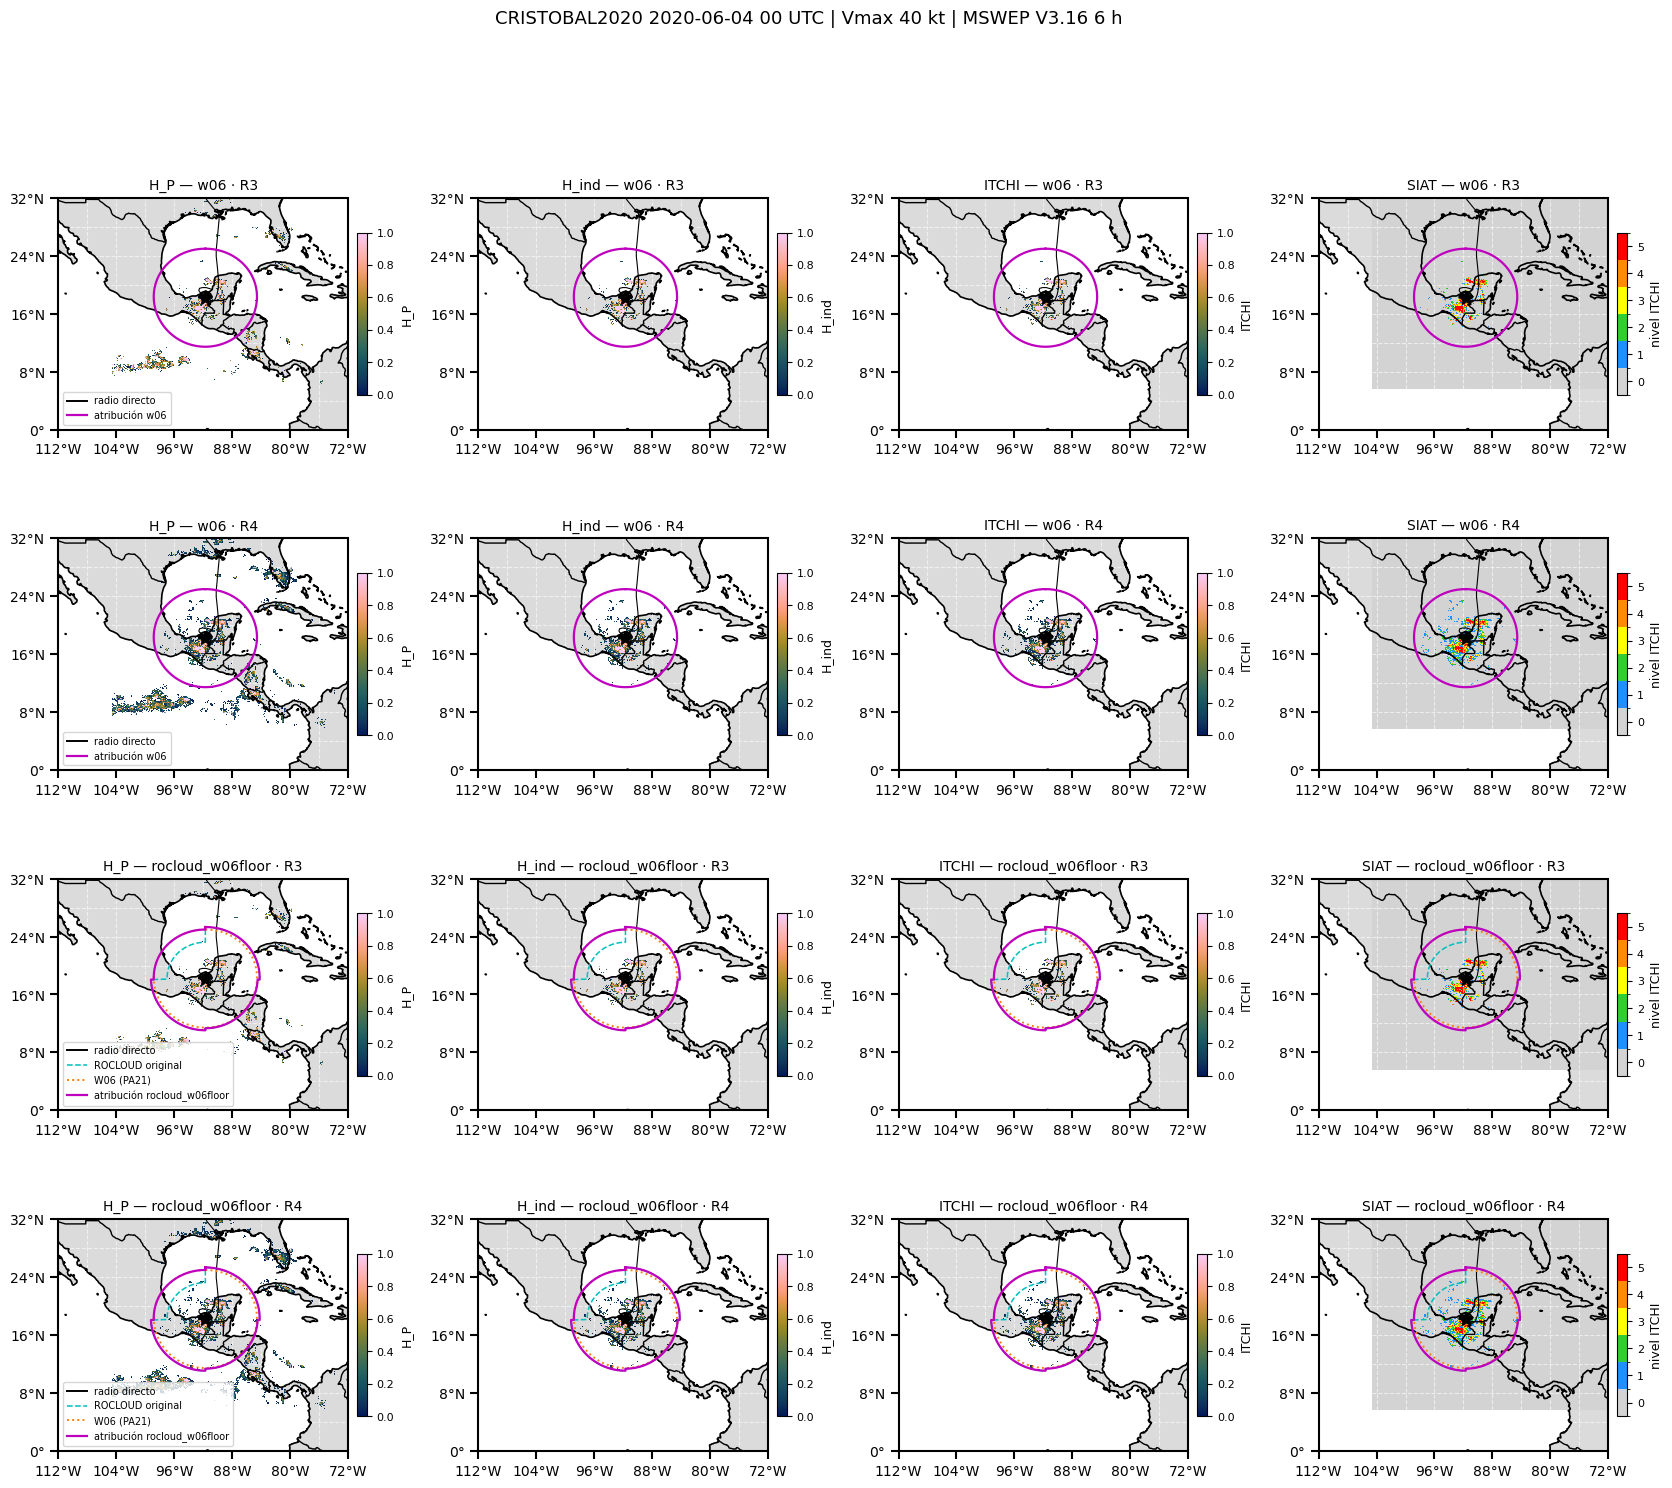

In [38]:
# Rejilla 4 experimentos x campos en SNAP_TIME
fig = plot_position_snapshot(SNAP_TIME)
fig.savefig(FIG_DIR / f"snapshot_{SNAP_TIME:%Y%m%d%H}.png", dpi=150, bbox_inches="tight")

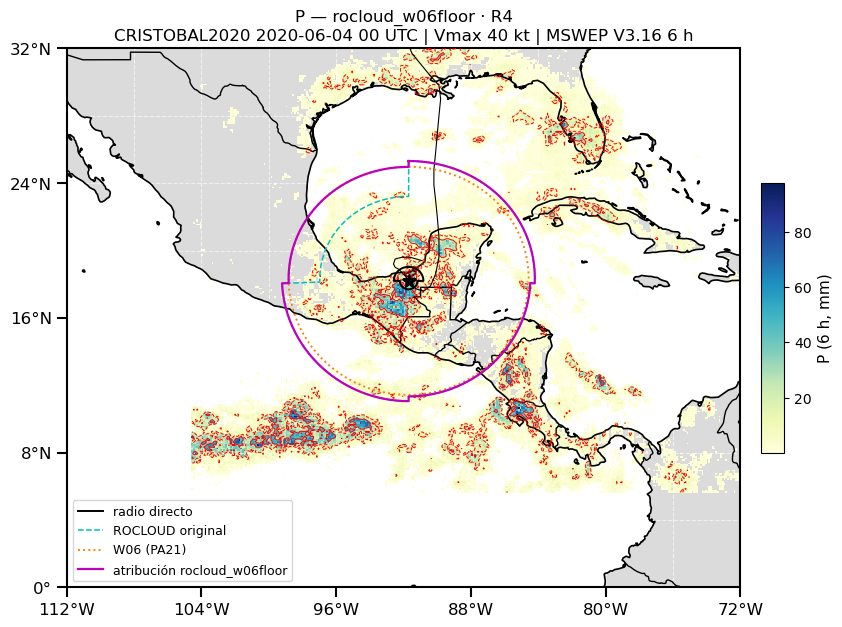

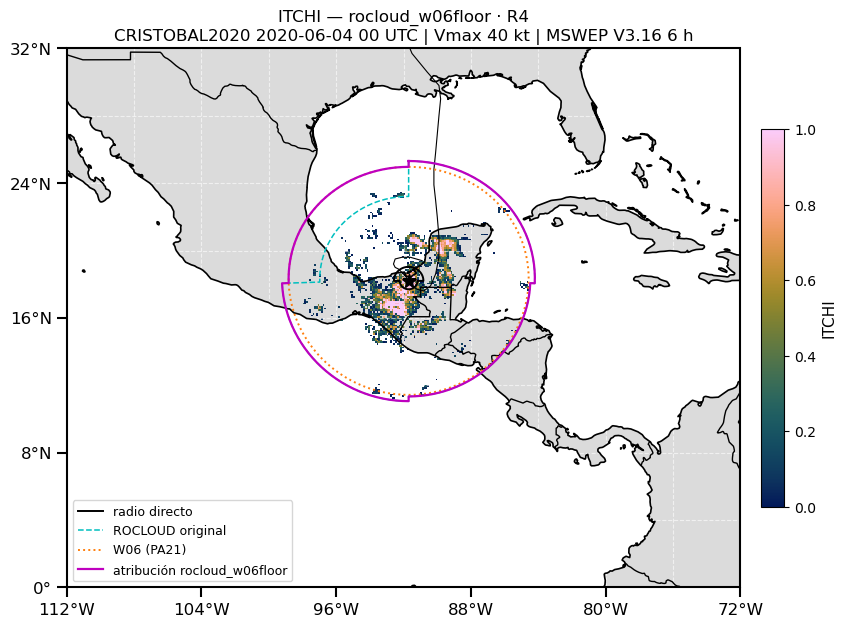

In [39]:
# Precipitación de 6 h con los contornos P = Q75 (discontinuo) y P = Q95 (continuo),
# y la sustitución de radios sobre el ITCHI de R4
fig = plot_position_field(SNAP_TIME, "rocloud_w06floor", "R4", "P", cbar_opts={"height": 0.5})
fig = plot_position_field(SNAP_TIME, "rocloud_w06floor", "R4", "ITCHI")

# Todos los campos y experimentos de una posición, cada uno en su propia figura
for attribution, ramp in EXPERIMENTS:
    for field in ("P",) + SNAP_FIELDS:
        fig = plot_position_field(SNAP_TIME, attribution, ramp, field)
        if fig is None:
            continue
        fig.savefig(FIG_DIR / f"{SNAP_TIME:%Y%m%d%H}_{attribution}_{ramp}_{field}.png",
                    dpi=150, bbox_inches="tight")
        plt.close(fig)

## 9. Métricas del índice por experimento

Áreas en km² (celdas ponderadas por $\cos\varphi$). Las diferencias se calculan respecto a `w06 · R3`, sobre la unión de las huellas (ITCHI_max > 0 en el experimento o en la referencia).

In [40]:
def event_metrics(ev: xr.Dataset, ref: xr.Dataset) -> dict:
    a = CELL_AREA_KM2
    x = np.nan_to_num(ev["ITCHI_max"].values)
    y = np.nan_to_num(ref["ITCHI_max"].values)
    direct = ev["M_direct"].any("time").values
    indirect = ev["M_indirect"].any("time").values & ~direct
    h_ind = np.nan_to_num(ev["H_ind"].max("time").values)
    union = (x > 0) | (y > 0)
    d, w = (x - y)[union], a[union]
    both, either = (x >= 0.5) & (y >= 0.5), (x >= 0.5) | (y >= 0.5)
    footprint = x > 0
    return {
        "snapshots": int(ev.sizes["time"]),
        "area_directa_km2": a[direct].sum(),
        "area_indirecta_km2": a[indirect].sum(),
        "area_ITCHI>=0.25_km2": a[x >= 0.25].sum(),
        "area_ITCHI>=0.50_km2": a[x >= 0.50].sum(),
        "area_ITCHI>=0.75_km2": a[x >= 0.75].sum(),
        "ITCHI_integrado_km2": (x * a).sum(),
        "ITCHI_max_medio_en_huella": (x * a)[footprint].sum() / a[footprint].sum(),
        "H_ind_medio_en_indirecta": (h_ind * a)[indirect].sum() / max(a[indirect].sum(), 1e-9),
        "dITCHI_medio_vs_ref": np.average(d, weights=w) if w.sum() else np.nan,
        "RMSD_vs_ref": np.sqrt(np.average(d**2, weights=w)) if w.sum() else np.nan,
        "frac_area_|d|>0.1": w[np.abs(d) > 0.1].sum() / w.sum() if w.sum() else np.nan,
        "Jaccard_ITCHI>=0.5": a[both].sum() / a[either].sum() if a[either].sum() else np.nan,
    }


metrics = pd.DataFrame([{"case": CASE, "attribution": a, "ramp": r,
                         **event_metrics(events[(a, r)], events[REFERENCE])}
                        for a, r in EXPERIMENTS]).set_index(["case", "attribution", "ramp"])
metrics.to_csv(DIAG_DIR / f"metricas_evento_{CASE.lower()}.csv")

for (a, r), ev in events.items():
    ev.to_netcdf(OUT_DIR / f"itchi_{CASE.lower()}_{a}_{r}_v316_6h.nc",
                 encoding={k: {"zlib": True, "complevel": 4} for k in ev.data_vars})
metrics.round(3)

snapshots  area_directa_km2  \
case          attribution      ramp                                
CRISTOBAL2020 w06              R3           43       1348123.544   
                               R4           43       1348123.544   
              rocloud_w06floor R3           43       1348123.544   
                               R4           43       1348123.544   

                                     area_indirecta_km2  area_ITCHI>=0.25_km2  \
case          attribution      ramp                                             
CRISTOBAL2020 w06              R3           2918364.997           1968655.070   
                               R4           2918364.997           2116059.905   
              rocloud_w06floor R3           5589381.406           2201649.386   
                               R4           5589381.406           2451640.186   

                                     area_ITCHI>=0.50_km2  \
case          attribution      ramp                         
CRISTOBAL2020 w06              R3             1813548.913   
                               R4             1817165.203   
              rocloud_w06floor R3             1974647.159   
                               R4             1978263.449   

                                     area_ITCHI>=0.75_km2  \
case          attribution      ramp                         
CRISTOBAL2020 w06              R3             1421096.088   
                               R4             1427972.904   
              rocloud_w06floor R3             1495400.586   
                               R4             1502277.402   

                                     ITCHI_integrado_km2  \
case          attribution      ramp                        
CRISTOBAL2020 w06              R3            1666376.735   
                               R4            1753062.608   
              rocloud_w06floor R3            1826440.043   
                               R4            1978469.239   

                                     ITCHI_max_medio_en_huella  \
case          attribution      ramp                              
CRISTOBAL2020 w06              R3                        0.784   
                               R4                        0.692   
              rocloud_w06floor R3                        0.742   
                               R4                        0.611   

                                     H_ind_medio_en_indirecta  \
case          attribution      ramp                             
CRISTOBAL2020 w06              R3                       0.172   
                               R4                       0.199   
              rocloud_w06floor R3                       0.118   
                               R4                       0.144   

                                     dITCHI_medio_vs_ref  RMSD_vs_ref  \
case          attribution      ramp                                     
CRISTOBAL2020 w06              R3                  0.000        0.000   
                               R4                  0.034        0.075   
              rocloud_w06floor R3                  0.065        0.207   
                               R4                  0.096        0.207   

                                     frac_area_|d|>0.1  Jaccard_ITCHI>=0.5  
case          attribution      ramp                                         
CRISTOBAL2020 w06              R3                0.000               1.000  
                               R4                0.161               0.998  
              rocloud_w06floor R3                0.123               0.918  
                               R4                0.290               0.917

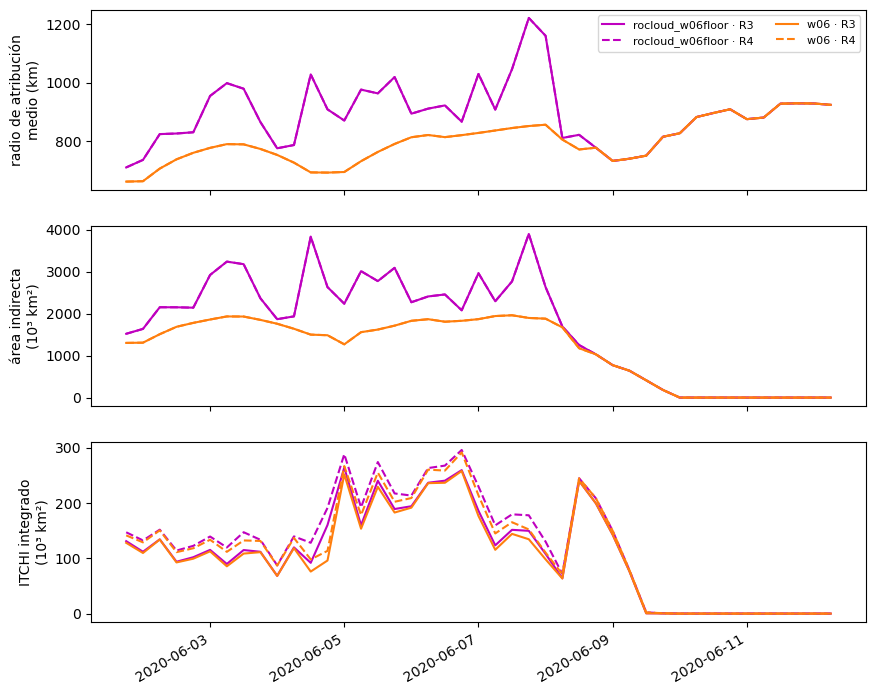

In [41]:
# Métricas por snapshot: radio medio, área indirecta e ITCHI integrado
per_time = []
for (a, r), ev in events.items():
    for t in ev["time"].values:
        snap = ev.sel(time=t)
        indirect = snap["M_indirect"].values & ~snap["M_direct"].values
        per_time.append(dict(case=CASE, attribution=a, ramp=r, time=pd.Timestamp(t),
                             area_indirecta_km2=CELL_AREA_KM2[indirect].sum(),
                             ITCHI_integrado_km2=(np.nan_to_num(snap["ITCHI"].values) * CELL_AREA_KM2).sum(),
                             H_ind_max=float(np.nanmax(snap["H_ind"].values))))
per_time = pd.DataFrame(per_time).merge(
    logs[["time", "attribution", "ramp", "attribution_mean_km"]], on=["time", "attribution", "ramp"])
per_time.to_csv(DIAG_DIR / f"metricas_snapshot_{CASE.lower()}.csv", index=False)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for (a, r), d in per_time.groupby(["attribution", "ramp"]):
    kw = dict(color="C1" if a == "w06" else "m", ls="-" if r == r_old else "--", label=label((a, r)))
    axes[0].plot(d["time"], d["attribution_mean_km"], **kw)
    axes[1].plot(d["time"], d["area_indirecta_km2"] / 1e3, **kw)
    axes[2].plot(d["time"], d["ITCHI_integrado_km2"] / 1e3, **kw)
axes[0].set_ylabel("radio de atribución\nmedio (km)")
axes[1].set_ylabel("área indirecta\n(10³ km²)")
axes[2].set_ylabel("ITCHI integrado\n(10³ km²)")
axes[0].legend(fontsize=8, ncol=2)
fig.autofmt_xdate()
fig.savefig(FIG_DIR / "metricas_snapshot.png", dpi=150, bbox_inches="tight")

## 10. Tabla conjunta (tras correr ambos casos)

In [42]:
paths = sorted(DIAG_DIR.glob("metricas_evento_*.csv"))
pd.concat([pd.read_csv(p) for p in paths]).round(3) if paths else None

,case,attribution,ramp,snapshots,area_directa_km2,area_indirecta_km2,area_ITCHI>=0.25_km2,area_ITCHI>=0.50_km2,area_ITCHI>=0.75_km2,ITCHI_integrado_km2,ITCHI_max_medio_en_huella,H_ind_medio_en_indirecta,dITCHI_medio_vs_ref,RMSD_vs_ref,frac_area_|d|>0.1,Jaccard_ITCHI>=0.5
0,CRISTOBAL2020,w06,R3,43,1348123.544,2918364.997,1968655.070,1813548.913,1421096.088,1666376.735,0.784,0.172,0.000,0.000,0.000,1.000
1,CRISTOBAL2020,w06,R4,43,1348123.544,2918364.997,2116059.905,1817165.203,1427972.904,1753062.608,0.692,0.199,0.034,0.075,0.161,0.998
2,CRISTOBAL2020,rocloud_w06floor,R3,43,1348123.544,5589381.406,2201649.386,1974647.159,1495400.586,1826440.043,0.742,0.118,0.065,0.207,0.123,0.918
3,CRISTOBAL2020,rocloud_w06floor,R4,43,1348123.544,5589381.406,2451640.186,1978263.449,1502277.402,1978469.239,0.611,0.144,0.096,0.207,0.290,0.917
0,ODILE2014,w06,R3,35,1217686.202,4165582.989,1610606.848,1249213.001,748631.457,1180585.032,0.596,0.100,0.000,0.000,0.000,1.000
1,ODILE2014,w06,R4,35,1217686.202,4165582.989,1817177.178,1253578.895,750655.977,1307770.969,0.504,0.128,0.049,0.090,0.235,0.997
2,ODILE2014,rocloud_w06floor,R3,35,1217686.202,5389885.624,1771590.779,1376372.531,818791.054,1297193.002,0.596,0.098,0.054,0.193,0.093,0.908
3,ODILE2014,rocloud_w06floor,R4,35,1217686.202,5389885.624,2020198.392,1380738.425,820815.574,1449369.504,0.498,0.124,0.092,0.194,0.309,0.905
